# 06 — Interpretability with SHAP

Which features push a prediction towards fighter A or fighter B, and by how much?
SHAP splits each fight's prediction into one piece per feature:

    score = 0 + piece from Elo + piece from age + ...   (40 pieces)

Each piece is that feature's **SHAP value** for that fight. Positive pushes towards
fighter A, negative towards fighter B. Units are **log-odds**: near 50%, +0.1 is about
+2.5 percentage points, +0.4 about +10.

Two adjustments, so the explanation matches what the model really predicts
(`modeling/explain.py`):

- **Both corners.** Every fight is predicted both ways round, so SHAP is computed
  both ways round and combined. The baseline is then exactly 0: a fight with no
  information is 50-50.
- **All 8 seeds.** The final predictor is 8 models; their SHAP values are averaged.

**Which fights.** SHAP never looks at who won, only at what the model predicted, so
looking at the validation years spends nothing. The main view is **validation
(2023–24)**: fights the model never trained on. The **training years (2014–22)** are
the cross-check: if both tell the same story, the patterns are stable. The test years
stay closed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.special import expit

from ufc_predictor.data.io import load_processed
from ufc_predictor.features import manifest
from ufc_predictor.modeling.explain import group_shap, shap_values, symmetric_score
from ufc_predictor.modeling.model import fit_models, predict_proba_mean
from ufc_predictor.modeling.split import chronological_split
from ufc_predictor.modeling.tune import load_params

featured = load_processed("fights_featured")
train, validation, _ = chronological_split(featured)      # the test years stay closed
X_train, y_train = manifest.make_xy(train)
X_val, _ = manifest.make_xy(validation)

# the final predictor: tuned settings, 8 seeds
models = fit_models(X_train, y_train, load_params())

val = shap_values(models, X_val)
trn = shap_values(models, X_train)
print(f"validation: {val.values.shape[0]:,} fights x {val.values.shape[1]} features | training: {trn.values.shape[0]:,} fights")

validation: 1,017 fights x 40 features | training: 4,309 fights


In [2]:
# checks: the pieces add up to the explained score, and that score tells the same
# story as the real prediction
S = symmetric_score(models, X_val)
p = predict_proba_mean(models, X_val)
assert np.allclose(val.values.sum(axis=1), S)
gap = np.abs(expit(S) - p)
print(f"pieces add up exactly; explained score vs real prediction: largest gap {gap.max():.2%}, "
      f"same pick in {((S > 0) == (p > 0.5)).mean():.0%} of fights")

# shorter names for the plots: drop the diff_prior_ / diff_static_ prefix
def short(column):
    for prefix in ("diff_prior_", "diff_static_", "diff_"):
        if column.startswith(prefix):
            return column[len(prefix):]
    return column

for e in (val, trn):
    e.feature_names = [short(c) for c in e.feature_names]
assert len(set(val.feature_names)) == len(val.feature_names)

pieces add up exactly; explained score vs real prediction: largest gap 1.92%, same pick in 100% of fights


## 1. Which families matter

Features that measure similar things split the credit between them: 32 striking
features each look small even if striking as a whole matters. So first, the SHAP
values are added up within each feature group from `manifest.py` (exact: the groups
still add up to the score). The bar is the average size of a group's push,
ignoring direction.

In [3]:
groups = manifest.feature_groups(train)
val_groups = group_shap(shap_values(models, X_val), groups)
trn_groups = group_shap(shap_values(models, X_train), groups)

table = pd.DataFrame({
    "columns": [len(groups[g]) for g in val_groups.feature_names],
    "validation": np.abs(val_groups.values).mean(axis=0),
    "training": np.abs(trn_groups.values).mean(axis=0),
}, index=val_groups.feature_names).sort_values("validation", ascending=False)
table["per_column"] = table["validation"] / table["columns"]
table.round(4)

,columns,validation,training,per_column
strength,1,0.2447,0.2417,0.2447
physical,5,0.2133,0.2200,0.0427
defence,11,0.1685,0.1671,0.0153
striking,13,0.1094,0.0985,0.0084
grappling,4,0.0855,0.0738,0.0214
cold_start,2,0.0238,0.0252,0.0119
record,3,0.0186,0.0177,0.0062
damage,1,0.0075,0.0072,0.0075
pace,0,0.0000,0.0000,NaN


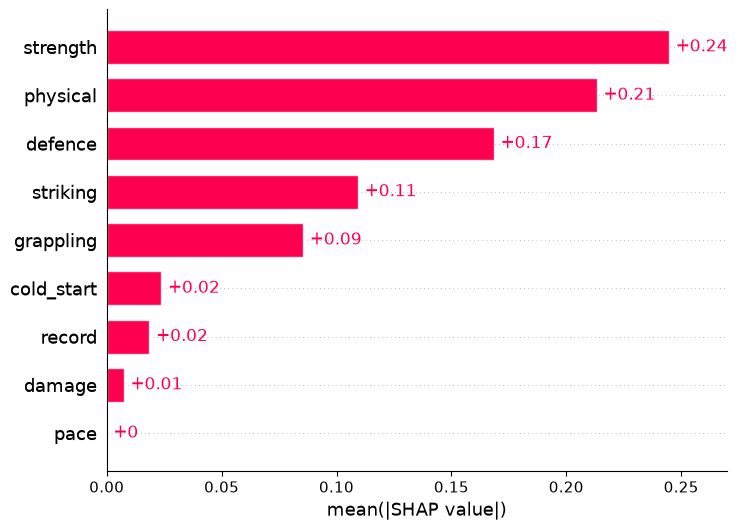

In [4]:
shap.plots.bar(val_groups, max_display=len(groups))

Two families carry the model: **strength**, the single Elo column (now weighting each win by how it
came), and **physical** (age gap, reach, height, weight class). The Elo column alone outweighs all 11
defence inputs together. Training and validation agree to within 0.015 for every group, and the top
five come in the same order as the permutation importance in `04_elo.ipynb` (the bottom three are
all close to zero there). Two different methods telling the same story is what makes it believable.

## 2. Beeswarm: validation years

One row per feature, the 15 that move predictions most. Each dot is one fight: how
far right or left it sits is how much that feature pushed the prediction; its colour
is the feature's value (red high, blue low). Every feature is fighter A minus fighter
B, so *red* means "A has more of it than B".

How to read a row: if red dots sit on the right, having more of this feature than
your opponent makes the model favour you.

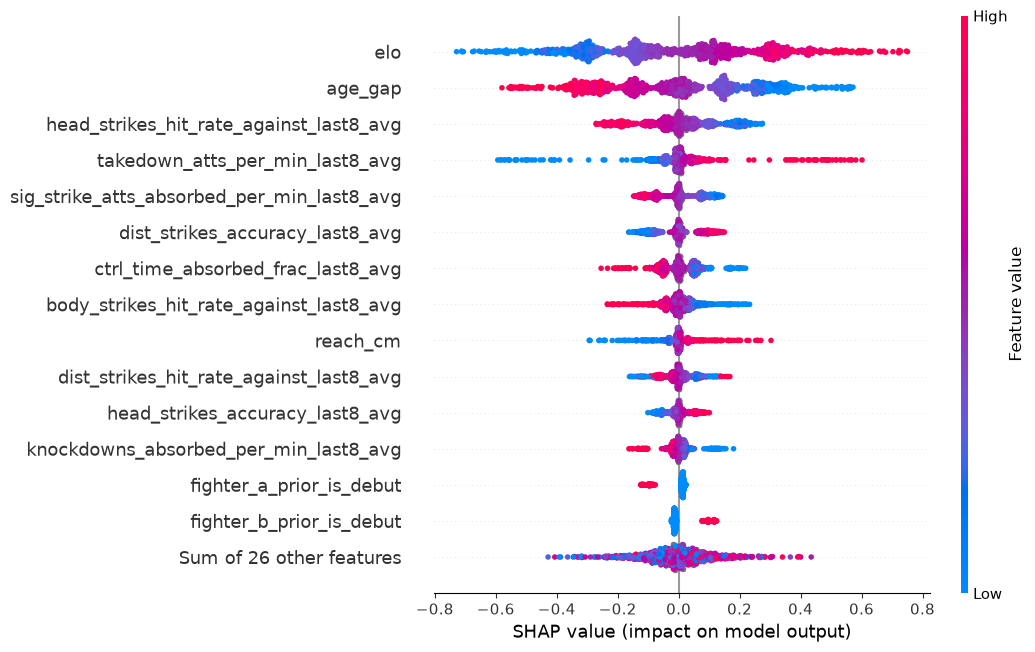

In [5]:
shap.plots.beeswarm(val, max_display=15)

## 3. Beeswarm: training years, the cross-check

The same plot on the 4,309 fights the model learned from. If the order and the
colour pattern match the validation plot, the model behaves the same way on fights it
has seen and fights it hasn't.

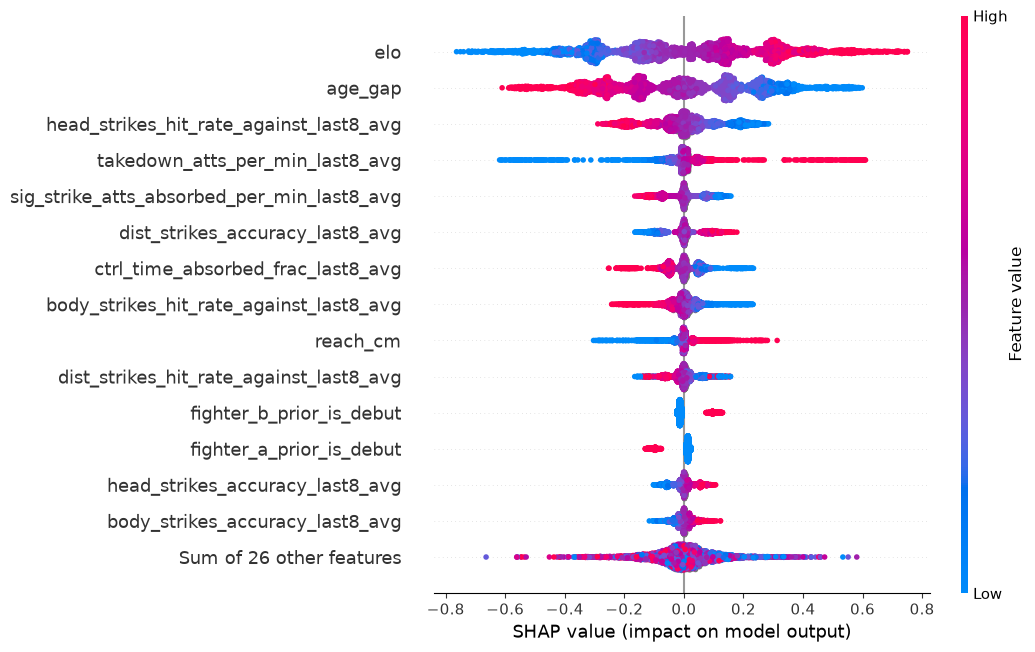

In [6]:
shap.plots.beeswarm(trn, max_display=15)

In [7]:
# the same comparison as numbers: the top 15 on validation, and where each ranks in training
def ranking(e):
    importance = pd.Series(np.abs(e.values).mean(axis=0), index=e.feature_names)
    return importance.sort_values(ascending=False)

v, t = ranking(val), ranking(trn)
top = pd.DataFrame({
    "validation_rank": range(1, 16),
    "mean_abs_shap": v.head(15).round(4).to_numpy(),
    "training_rank": [t.index.get_loc(f) + 1 for f in v.head(15).index],
}, index=v.head(15).index)
top

,validation_rank,mean_abs_shap,training_rank
elo,1,0.2447,1
age_gap,2,0.2053,2
head_strikes_hit_rate_against_last8_avg,3,0.0856,3
takedown_atts_per_min_last8_avg,4,0.0609,4
sig_strike_atts_absorbed_per_min_last8_avg,5,0.0576,5
dist_strikes_accuracy_last8_avg,6,0.0523,6
ctrl_time_absorbed_frac_last8_avg,7,0.0477,7
body_strikes_hit_rate_against_last8_avg,8,0.0410,8
reach_cm,9,0.0311,9
dist_strikes_hit_rate_against_last8_avg,10,0.0311,10


## 4. Dependence plots: the shape of each effect

One plot per feature, for the four that matter most. The x-axis is the feature's
value (A minus B), the y-axis its SHAP value: how far it moved the prediction for
that fight, measured from 50-50. A straight line means "every extra unit counts the
same"; a curve that flattens means "differences beyond a point stop mattering".

The colour is a second feature, the one SHAP finds interacts most with this one. If
the red and blue dots separate vertically, the effect of the x-axis feature depends
on the colour feature.

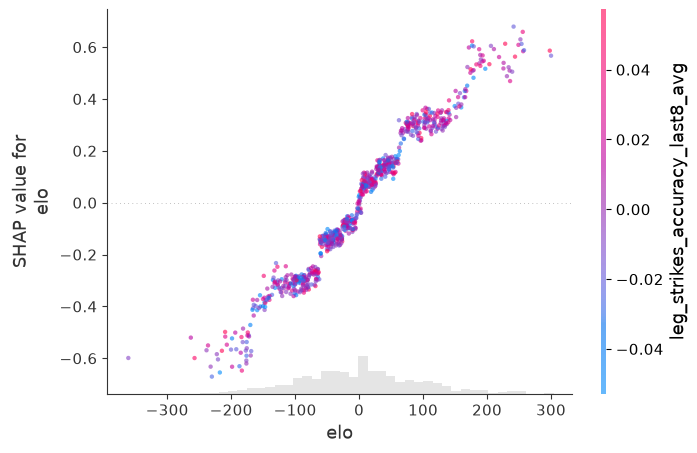

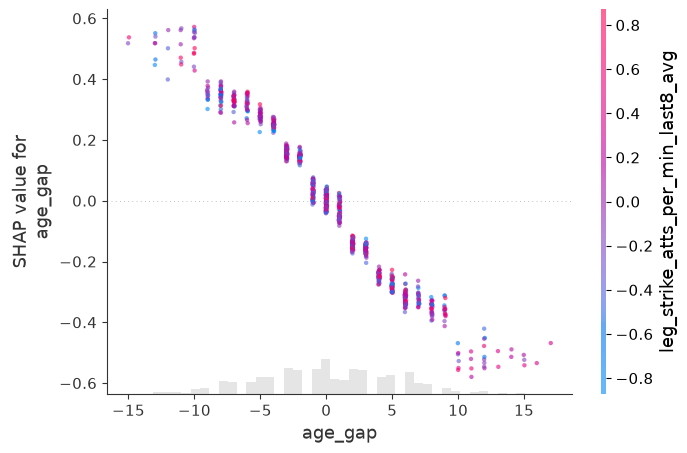

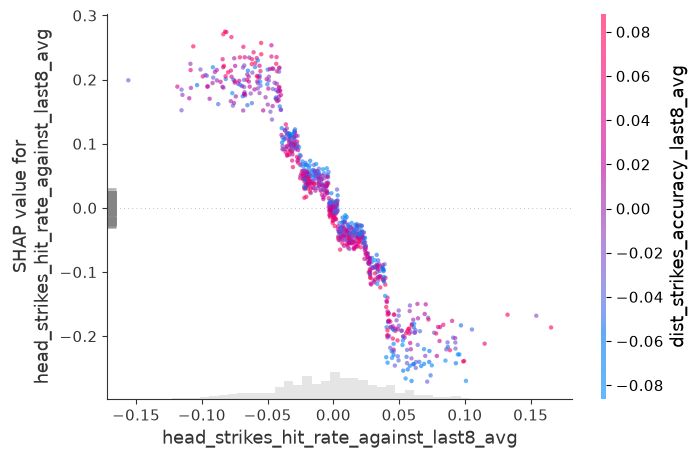

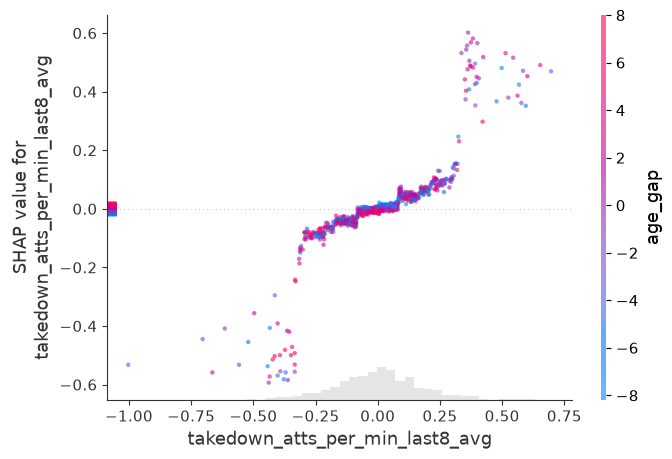

In [8]:
for feature in v.index[:4]:
    shap.plots.scatter(val[:, feature], color=val, alpha=0.6, dot_size=10)

## 5. Interactions: does one input's push depend on another's?

Sections 1-4 give each input one push per fight. **Interactions** split that push further, the way
a factorial experiment separates the effect of temperature on its own from the temperature ×
pressure term:

- the input's **main effect**: its push on its own;
- one **pair effect** per other input: the extra push it gets only because of that input's value.
  For example "the head-strike accuracy gap counts for more because the head-defence gap points
  the same way".

Per fight this is a 40 × 40 table (`modeling.explain.shap_interaction_values`, with the same two
adjustments: both corners, all 8 seeds). The diagonal holds the main effects; each pair's effect is
split in half between its two off-diagonal cells; each row adds up exactly to that input's SHAP
value from sections 1-4, and the whole table to the fight's score. Nothing about the predictions
changes: this only splits them into finer pieces.

Three reading rules:

1. **It explains the model, not the fight.** A pair effect says how the model combines two
   numbers, not that one skill causes another to matter in the cage.
2. **Overlapping inputs make "interactions" that are really double-count corrections.** In a
   designed experiment the factors are set independently, so an A × B term is a real effect. Here
   inputs overlap: Elo and win rate are both built from past results. When both favour the same
   fighter, the model adds up *less* than the two separately, so as not to count the same evidence
   twice. Such a pair is labelled **overlap**; a pair that adds *more* when both inputs agree is
   **reinforcing**.
3. **Every input is a gap, fighter A minus fighter B.** So a pair can say "the accuracy gap counts
   more when the defence gap is big too", but never "A's attack against B's defence": the model is
   never given that combination.

In [9]:
from ufc_predictor.modeling.explain import group_interactions, shap_interaction_values
from ufc_predictor.modeling.model import SYMMETRIC_FEATURES

# one 40 x 40 table per fight (about a minute: 8 models, both corners, 5,300 fights)
inter_val = shap_interaction_values(models, X_val)
inter_trn = shap_interaction_values(models, X_train)
assert np.allclose(inter_val.sum(axis=2), val.values)     # each row adds up to that input's SHAP value
assert np.allclose(inter_trn.sum(axis=2), trn.values)

names = val.feature_names                                  # the short names from above
n = len(names)
diag = np.arange(n)
print(f"validation: {inter_val.shape[0]:,} tables of {n} x {n} | training: {inter_trn.shape[0]:,}")

validation: 1,017 tables of 40 x 40 | training: 4,309


### 5a. How additive is the model?

If every input only pushed on its own, the main effects alone would make up the whole score. So:
how much of the score do they account for, and how far does the probability move if the pair
effects are left out? (A thought experiment: the model itself always uses everything.)

In [10]:
def additivity(values):
    score = values.sum(axis=(1, 2))
    main = values[:, diag, diag].sum(axis=1)
    change = np.abs(expit(score) - expit(main)) * 100
    return pd.Series({
        "share of the score's variation from main effects": 1 - np.var(score - main) / np.var(score),
        "probability change without the pairs: average (points)": change.mean(),
        "probability change without the pairs: largest (points)": change.max(),
        "fights whose pick would flip without the pairs": ((score > 0) != (main > 0)).mean(),
    })

pd.DataFrame({"validation": additivity(inter_val), "training": additivity(inter_trn)}).round(3)

,validation,training
share of the score's variation from main effects,0.937,0.931
probability change without the pairs: average (points),2.382,2.498
probability change without the pairs: largest (points),12.353,13.911
fights whose pick would flip without the pairs,0.066,0.068


### 5b. Which families interact

The pair effects added up between feature families (the groups of section 1), then averaged
ignoring direction. The diagonal is interaction *within* a family, between its own inputs. Main
effects are left out, so this is only the extra push from combinations.

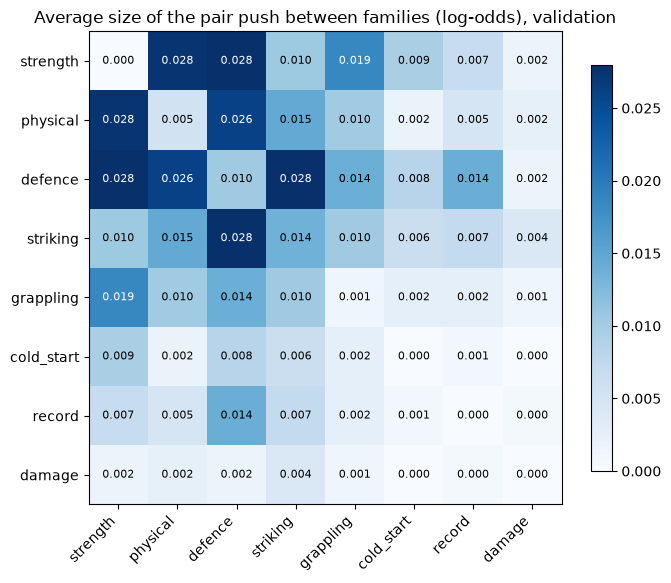

training vs validation: largest difference in any cell 0.0018


In [11]:
families = {g: [short(c) for c in columns] for g, columns in groups.items() if columns}
fam_val = group_interactions(inter_val, names, families)
fam_trn = group_interactions(inter_trn, names, families)
order = [g for g in table.index if g in families]          # families in order of their own importance

fig, ax = plt.subplots(figsize=(7, 6))
grid = fam_val.loc[order, order]
im = ax.imshow(grid, cmap="Blues")
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        v = grid.iloc[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                color="white" if v > grid.to_numpy().max() * 0.6 else "black")
ax.set_title("Average size of the pair push between families (log-odds), validation")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
print(f"training vs validation: largest difference in any cell {np.abs(fam_val - fam_trn).to_numpy().max():.4f}")

### 5c. The strongest pairs, and which ones are consistent

One row per pair of inputs, the 15 strongest on validation:

- **mean_abs**: the average size of the pair's push, in log-odds; **mean_points**: the same as
  win probability (percentage points).
- **fights_1pt**: the share of fights where the pair moves the probability by at least 1 point.
- **pattern**: take the fights where both inputs favour the same fighter. **Overlap** means the
  pair takes some of that edge back (double counting removed); **reinforcing** means it adds to
  it. Which fighter an input favours comes from its own main effect (e.g. higher Elo favours you,
  an older age gap favours your opponent). Pairs with weight class or women's bout are
  **context**: they say an input counts more or less depending on the division, where nobody is
  "favoured". **never agree**: the two inputs (almost) never favour the same fighter, e.g. the two
  debut flags.
- **consistent**: in the top 20 on both validation and training, with the same pattern on both.
  Only consistent pairs are worth describing anywhere.

In [12]:
context = {short(c) for c in SYMMETRIC_FEATURES}

def pair_table(values, X):
    """One row per pair: average size, how often it is worth 1 point or more, and its pattern."""
    score = values.sum(axis=(1, 2))
    x = X.to_numpy(dtype=float)
    # +1: having more of this input than your opponent favours you; -1: it favours your opponent
    favours = np.sign([np.nansum(x[:, k] * values[:, k, k]) for k in range(n)])
    rows = []
    for i in range(n):
        for j in range(i + 1, n):
            effect = 2 * values[:, i, j]                          # both halves of the pair
            points = np.abs(expit(score) - expit(score - effect)) * 100
            a = np.sign(x[:, i]) * favours[i]                     # +1: input i favours fighter A here
            b = np.sign(x[:, j]) * favours[j]
            agree = (a == b) & (a != 0)
            if names[i] in context or names[j] in context:
                pattern = "context"
            elif agree.sum() < 30:                                # e.g. the two debut flags never agree
                pattern = "never agree"
            else:
                pattern = "overlap" if (effect * a)[agree].mean() < 0 else "reinforcing"
            rows.append({"pair": f"{names[i]} x {names[j]}", "mean_abs": np.abs(effect).mean(),
                         "mean_points": points.mean(), "fights_1pt": (points >= 1).mean(), "pattern": pattern})
    return pd.DataFrame(rows).set_index("pair").sort_values("mean_abs", ascending=False)

pairs_val, pairs_trn = pair_table(inter_val, X_val), pair_table(inter_trn, X_train)
top_pairs = pairs_val.head(15).copy()
top_pairs["training_rank"] = [pairs_trn.index.get_loc(p) + 1 for p in top_pairs.index]
top_pairs["training_pattern"] = pairs_trn.loc[top_pairs.index, "pattern"].to_numpy()
top_pairs["consistent"] = ((top_pairs["training_rank"] <= 20)
                           & (top_pairs["pattern"] == top_pairs["training_pattern"]))
print(f"{len(pairs_val)} pairs; worth 0.005 log-odds or more on average: {(pairs_val['mean_abs'] >= 0.005).sum()}")
top_pairs.round(4)

780 pairs; worth 0.005 log-odds or more on average: 26


,mean_abs,mean_points,fights_1pt,pattern,training_rank,training_pattern,consistent
pair,,,,,,,
elo x age_gap,0.0270,0.6122,0.1888,overlap,1,overlap,True
elo x head_strikes_hit_rate_against_last8_avg,0.0143,0.3274,0.0098,overlap,2,overlap,True
body_strikes_hit_rate_against_last8_avg x streak,0.0124,0.2871,0.0000,reinforcing,3,reinforcing,True
head_strikes_hit_rate_against_last8_avg x age_gap,0.0107,0.2474,0.0000,reinforcing,4,reinforcing,True
dist_strikes_accuracy_last8_avg x head_strikes_hit_rate_against_last8_avg,0.0095,0.2164,0.0334,reinforcing,9,reinforcing,True
elo x takedown_atts_per_min_last8_avg,0.0092,0.2071,0.0521,overlap,7,overlap,True
body_strikes_hit_rate_against_last8_avg x age_gap,0.0091,0.2093,0.0000,reinforcing,5,reinforcing,True
elo x tot_strikes_hit_rate_against_last8_avg,0.0081,0.1877,0.0000,overlap,8,overlap,True
ctrl_time_absorbed_frac_last8_avg x reach_cm,0.0080,0.1878,0.0236,reinforcing,6,reinforcing,True


### 5d. The shape of the strongest reinforcing pairs

For up to three reinforcing pairs from the table: the x-axis is the first input (A minus B), the
y-axis the pair's push for that fight (both halves), the colour the second input. If the push
grows with the x-axis when the colour is extreme, the first input counts more when the second
one is large.

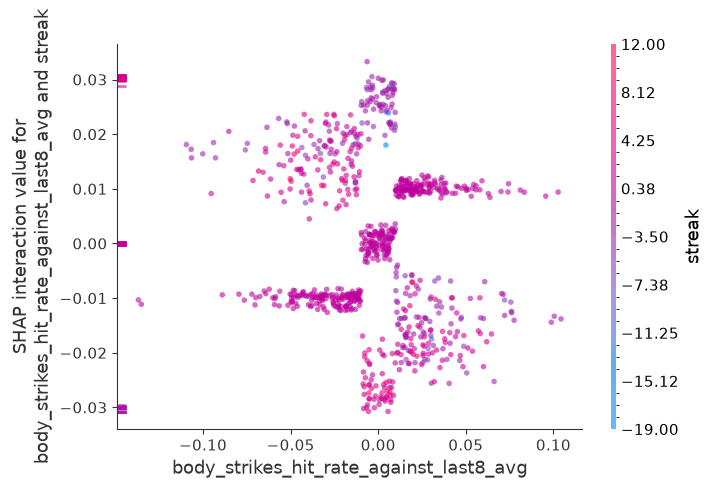

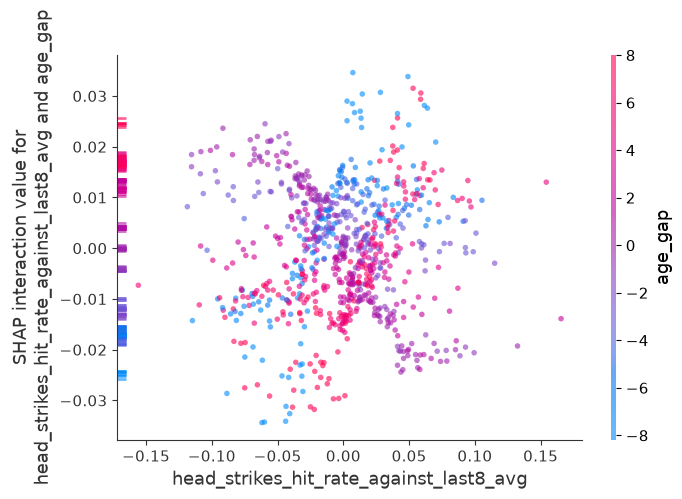

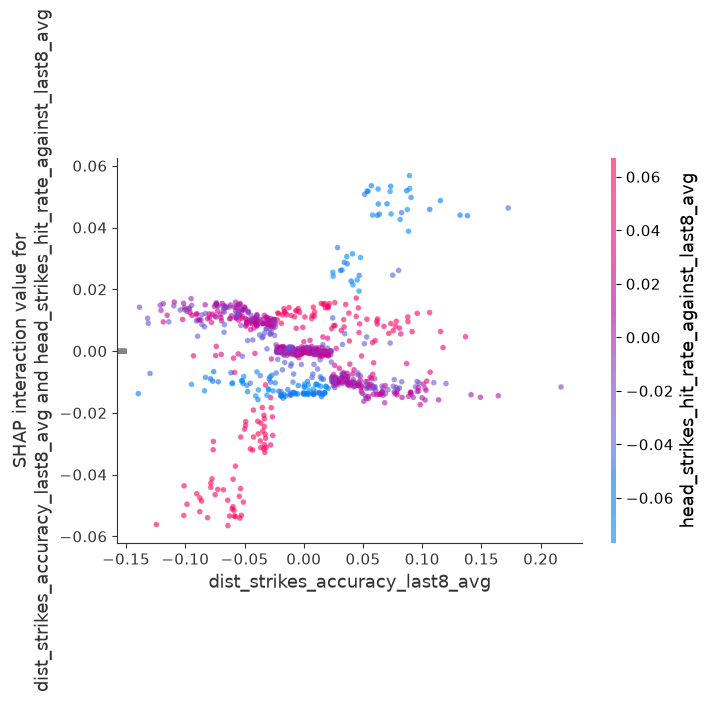

In [13]:
X_val_short = X_val.rename(columns=short)
reinforcing = top_pairs.index[top_pairs["pattern"] == "reinforcing"][:3]
for pair in reinforcing:
    first, second = pair.split(" x ")
    shap.dependence_plot((first, second), inter_val, X_val_short, alpha=0.6, dot_size=10)
if len(reinforcing) == 0:
    print("no reinforcing pair among the top 15")

### 5e. How often is a pair big enough to mention?

The fight-preview pages could say "this edge counts for more because of that input" only when the
pair really moves the prediction. Per fight: the largest pair effect, next to the largest single
input.

In [14]:
score = inter_val.sum(axis=(1, 2))
upper = np.triu_indices(n, 1)
pair_points = np.abs(expit(score)[:, None] - expit(score[:, None] - 2 * inter_val[:, upper[0], upper[1]])) * 100
main_points = np.abs(expit(score)[:, None] - expit(score[:, None] - inter_val[:, diag, diag])) * 100
largest_pair, largest_main = pair_points.max(axis=1), main_points.max(axis=1)
pd.Series({
    "largest single input, typical fight (points)": np.median(largest_main),
    "largest pair, typical fight (points)": np.median(largest_pair),
    "largest pair, 1 fight in 10 (points)": np.percentile(largest_pair, 90),
    "largest pair, any fight (points)": largest_pair.max(),
    "fights with a pair worth >= 1 point": (largest_pair >= 1).mean(),
    "fights with a pair worth >= 2 points": (largest_pair >= 2).mean(),
    "fights with a pair worth >= 3 points": (largest_pair >= 3).mean(),
}).round(3)

largest single input, typical fight (points)    7.749
largest pair, typical fight (points)            0.889
largest pair, 1 fight in 10 (points)            1.576
largest pair, any fight (points)                3.067
fights with a pair worth >= 1 point             0.400
fights with a pair worth >= 2 points            0.043
fights with a pair worth >= 3 points            0.001
dtype: float64

### What the interactions show

1. **The model is mostly additive.** Main effects make up 94% of the score's variation (93% on
   training). Leaving the pair effects out would move a fight's probability by 2.4 points on
   average (at most 12) and flip the pick in 6.6% of fights, all close calls: none of them was
   more than 7.4 points from 50-50.
2. **The patterns are stable.** All 15 strongest pairs on validation are in training's top 20,
   with the same pattern, and the family table differs by at most 0.002 between the two.
3. **The strongest pairs are overlap with Elo.** Elo × age gap is the largest (0.6 points on
   average, at least 1 point in 19% of fights), then Elo with head defence, takedown attempts,
   overall defence, control time, takedown accuracy and accuracy at range. When Elo and one of
   these point at the same fighter, the model adds up less than the two separately: Elo
   summarises results those same skills helped earn, so part of the evidence is counted once.
4. **A few offence × defence pairs reinforce, as a fight fan would expect.** The clearest is
   **accuracy at range × head defence** (third plot): when fighter A is both much more accurate
   at range *and* much harder to hit in the head, the pair adds about 0.05 log-odds (about 1.2
   points) on top of the two separate pushes. In the opposite case it pushes the same amount the
   other way, and in between it does little. The same idea shows up for the body (body-strike
   accuracy × body defence: at least 1 point in 5% of fights), and reach reinforces time spent
   controlled (at least 1 point in 2% of fights). The other reinforcing pairs (defence × age gap,
   body defence × streak, two accuracy measures together) are step-shaped and small: never worth
   1 point. Not every offence × defence pair reinforces: takedown attempts × takedown defence is
   overlap (at least 1 point in 6.5% of fights).
5. **Families:** the biggest links are strength (Elo) with physical (age) and with defence, and
   defence with striking (0.028 each); damage interacts with nothing.
6. **Interactions are small next to the inputs themselves.** In a typical fight the largest pair
   is worth 0.9 points against 7.7 for the largest single input. A pair reaches 1 point in 40% of
   fights, 2 points in 4%, 3 points almost never (1 fight in 1,000). So a fight preview could
   mention an interaction only in a minority of fights, and only the consistent reinforcing pairs
   above, phrased as how the model weighs things ("gives the accuracy edge a little extra weight
   because the defence gap points the same way"), never as a cause or as "significant".

## What it shows

1. **Two features do most of the work.** Elo (0.245) and age gap (0.205) each move predictions
   more than twice as much as the next feature, how often the fighter gets hit in the head (0.086).
2. **Every direction makes sense.** Higher Elo, younger than your opponent, harder to hit, more
   takedown and submission attempts, more accurate: the model favours you. Facing more strikes,
   spending more time controlled, suffering more knockdowns: it favours your opponent.
3. **Age gap is close to a straight line.** About 0.045 log-odds per year, roughly one percentage
   point, flattening beyond about 10 years. A 10-year gap is worth about 11 points.
4. **Elo is close to a straight line too, and steeper than the classic rating.** About 0.25
   log-odds per 100 rating points (6 percentage points), up to about ±0.6 (±15 points). The weighted
   ratings sit closer together, so each point means more.
5. **The fight stats are ramps that level off**: beyond a few points of difference, more adds
   nothing. The grey strip on the left of those plots is fights where the feature is missing (a
   debutant): no push either way.
6. **Interactions are small but real** (section 5). Main effects make up 94% of the score; in a
   typical fight the largest pair is worth 0.9 points against 7.7 for the largest single input.
   The strongest pairs are Elo overlapping with other inputs; a few offence × defence pairs
   reinforce (accuracy at range × head defence), the same in training and validation.
7. **The story is stable.** Training and validation rank the same top features, within a few places.